# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.9710
Accuracy CV:   0.9791

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



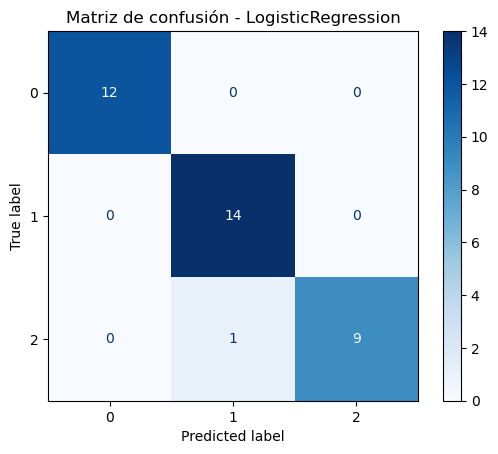

In [4]:
y_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test: {test_accuracy:.4f}")
print(f"F1 macro test: {test_f1_macro:.4f}")
print(f"Accuracy CV:   {training_metadata['cv_accuracy']:.4f}")
print()
print(classification_report(y_test, y_pred, digits=4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title(f"Matriz de confusión - {training_metadata['champion']}")
plt.show()

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

- **Coherencia con CV:** la accuracy en test es **0.972** y el F1 macro **0.971**. Ambos están dentro del intervalo esperado según la CV (0.979 ± 0.028), así que el desempeño generaliza como se estimó.
- **Clases confundidas:** solo hay un error en 36 muestras: un vino de la clase 2 se predijo como clase 1. La clase 0 se clasifica perfectamente. Esto coincide con el EDA: las clases 1 y 2 tienen `proline` parecido (aprox. 526 frente a 623), mientras que la clase 0 se separa claramente.
- **Sobreajuste:** no hay evidencia relevante. La caída de CV a test es de menos de 1 pp. Con solo 36 muestras de test, cada error vale aprox. 2.8 pp, así que la diferencia no es significativa.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    missing = [col for col in feature_columns if col not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    X = records[feature_columns]
    result = pd.DataFrame(index=records.index)
    result["prediction"] = model.predict(X)
    probabilities = model.predict_proba(X)
    for i, cls in enumerate(model.classes_):
        result[f"proba_{cls}"] = probabilities[:, i]
    return result

# Validación del esquema: debe fallar si falta una columna
try:
    predict(X_test.drop(columns=["proline"]).iloc[:1])
except ValueError as error:
    print("Validación OK ->", error)

Validación OK -> Faltan columnas requeridas: ['proline']


## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch_predictions.round(4)

,prediction,proba_0,proba_1,proba_2
0,0,0.9997,0.0003,0.0000
1,1,0.0071,0.5404,0.4525
2,0,0.9920,0.0077,0.0003
3,1,0.2900,0.7075,0.0026
4,1,0.0330,0.9623,0.0047


## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "best_params": training_metadata["best_params"],
    "cv_accuracy": training_metadata["cv_accuracy"],
    "test_accuracy": float(test_accuracy),
    "test_f1_macro": float(test_f1_macro),
    "n_test": len(test_df),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2, ensure_ascii=False, default=str))

{
  "model": "LogisticRegression",
  "best_params": {
    "model__C": 1
  },
  "cv_accuracy": 0.9790640394088669,
  "test_accuracy": 0.9722222222222222,
  "test_f1_macro": 0.9709618874773139,
  "n_test": 36
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | LogisticRegression (C = 1) con imputación por mediana y StandardScaler |
| Accuracy CV | 0.979 ± 0.028 (5 folds estratificados) |
| Accuracy test | 0.972 (35/36) |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 → clase 1 (1 caso) |
| Principal limitación | Dataset muy pequeño (178 filas, 36 en test), lo que da métricas con alta varianza; las predicciones con probabilidad dividida entre clases 1 y 2 (p. ej. 0.54 / 0.45) son menos fiables |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.